# Adult Jaundice Detection from Eye Images — V3 (journal version)
### Eye-standardised, text-free, shortcut-audited comparison of five literature baselines and the proposed Sclera-Guided Hybrid Fusion (SGHF)

**Author:** Md. Abu Sayem (MRIIRS, Faridabad)

**What changed from V1 (and why)**

| V1 problem (seen in the real run) | V2 fix |
|---|---|
| Colour-threshold "sclera mask" picked forehead / skin / background | Sclera from **manual polygons** (COCO JSON, e.g. makesense.ai) where available, otherwise **CLIPSeg** text-prompted segmentation; full-dataset **mask QC gallery** |
| Several jaundice images carry **text / logos** ("Symptoms of Jaundice", hospital logos) → label leakage | **OCR (EasyOCR) text filter**, flagged images removed and shown in a gallery |
| Border-only view gave AUC ≈ 0.89 → models learned photo style, not sclera colour | Main protocol uses **eye-region crops** for every model; shortcut audit now compares **raw image vs eye crop** |
| SGHF grid hit its upper limits | Wider grid (C, PCA size) |
| Weak frozen backbone | **DINOv2 ViT-S/14** frozen features (EfficientNet-B0 fallback only if allowed) |

**New in V3 (after inspecting every V2 QC page)**

| V2 finding | V3 fix |
|---|---|
| Masks often contained the **iris**, mostly blue/green irises in *normal* stock photos → colour features partly measured **eye colour** | Iris removed by a **hue rule** (sclera is never blue/green) **and** a CLIPSeg *iris* prompt; removed fractions are reported per class |
| Normal = macro stock photos (many light irises); jaundice = clinical photos (mostly brown irises) | Automatic **iris-colour** labelling + **dark-iris-only subgroup analysis** |
| Fingers / gloves pulling the eyelid appear only in jaundice photos | **Sensitivity analysis** excluding those images |
| Watermarks missed by OCR, collages, infants | Pre-filled, **visually verifiable exclusion lists** (gallery saved) |
| Many jaundice photos have a global yellow colour cast | **Periocular-skin-only control** + grey-world ablation |
| SGHF grid hit its limits again | Grid widened further |

**Pipeline:** load → near-duplicate grouping → OCR text filter → sclera + eye-region segmentation → QC → features → 6 models × repeated stratified group k-fold → metrics, CIs, DeLong / Nadeau–Bengio → ablation → shortcut audit → (optional) external validation → paper tables, figures, `paper_numbers.json`.

**How to run (Colab, T4 GPU):** *Runtime → Run all*. Everything runs automatically with CLIPSeg masks.
For the strongest paper, do the **manual sclera annotation** once (Section 6) and run again — the notebook then uses your polygons automatically.

> Honesty rules for the manuscript: baselines are *re-implementations of each paper's core method on this dataset*; the dataset is web-scraped and not clinically validated; report every number from the CSV files exactly, including when a baseline beats the proposed model.

In [2]:
# ===== 0. Install =====
import sys, subprocess
def _pip(*p): subprocess.run([sys.executable, "-m", "pip", "install", "-q", *p], check=False)
_pip("datasets>=2.18", "imagehash", "opencv-python-headless", "easyocr", "transformers>=4.38")

## 1. Configuration

In [3]:
import os, json
CFG = dict(
    DATA_SOURCE     = "hf",                          # "hf" or "folder"
    HF_ID           = "Bleachcarte/Jaundice_Dataset",
    FOLDER          = "/content/data",               # FOLDER/jaundice/*, FOLDER/normal/*
    EXTERNAL_FOLDER = "",                            # optional second dataset, same layout
    OUT             = "/content/results_v3",
    # --- sclera segmentation ---
    SCLERA_COCO     = "/content/sclera_coco.json",   # manual polygons (Section 6). Missing file -> CLIPSeg for all images
    SEG_MODEL       = "CIDAS/clipseg-rd64-refined",
    EXCLUDE_IDS     = [],                            # any extra image IDs to drop after looking at the QC gallery
    # IDs below were found by visual inspection of the V2 QC pages (HF dataset, load order).
    # They are shown in fig02b_manual_exclusions.png -> check every tile before trusting them.
    EXCLUDE_WATERMARK = [41, 114, 124, 135, 171, 172, 174, 185, 190, 196, 199, 211, 218, 222, 226, 265,
                         282, 289, 305, 311, 316, 318],                 # watermarks / overlaid text missed by OCR
    EXCLUDE_COMPOSITE = [133, 221, 264, 302, 309],                       # collages, split faces, figure panels
    EXCLUDE_CHILD     = [46, 144, 155, 186, 231, 250],                   # infants / children (dataset is "adult")
    FINGER_IDS        = [145, 146, 152, 162, 180, 194, 198, 200, 204, 213, 215, 228, 236, 237,
                         241, 243, 244, 245, 247, 251, 298, 310, 313, 317],  # finger / glove pulling the eyelid
    IRIS_HUE_FILTER = True,                          # drop blue/green saturated pixels from the sclera mask
    # --- text filter ---
    OCR_FILTER      = True,
    OCR_MIN_CONF    = 0.40,
    # --- backbone for SGHF ---
    BACKBONE        = "dinov2_vits14",               # or "efficientnet_b0"
    ALLOW_FALLBACK  = False,                         # True only for offline testing: never for paper results
    # --- evaluation ---
    SEED = 42, N_SPLITS = 5, N_REPEATS = 3,
    IMG = 224, EPOCHS = 25, PATIENCE = 6, BATCH = 16, LR = 1e-4,
    PHASH_THR = 6, PRETRAINED = True, N_BOOT = 2000, THRESHOLD = 0.5,
    RAW_CNN_AUDIT = True,
    MANUAL_LISTS_FOR = "Bleachcarte/Jaundice_Dataset",  # the pre-filled ID lists apply only to this dataset                            # fine-tune VGG16 on raw images once, for the shortcut audit
)
for k in CFG:                                        # JX_<KEY> environment overrides (automated tests)
    v = os.environ.get("JX_" + k)
    if v is not None:
        try: CFG[k] = json.loads(v)
        except Exception: CFG[k] = v
os.makedirs(f'{CFG["OUT"]}/figures/qc', exist_ok=True)
print(json.dumps(CFG, indent=1))

{
 "DATA_SOURCE": "hf",
 "HF_ID": "Bleachcarte/Jaundice_Dataset",
 "FOLDER": "/content/data",
 "EXTERNAL_FOLDER": "",
 "OUT": "/content/results_v3",
 "SCLERA_COCO": "/content/sclera_coco.json",
 "SEG_MODEL": "CIDAS/clipseg-rd64-refined",
 "EXCLUDE_IDS": [],
 "EXCLUDE_WATERMARK": [
  41,
  114,
  124,
  135,
  171,
  172,
  174,
  185,
  190,
  196,
  199,
  211,
  218,
  222,
  226,
  265,
  282,
  289,
  305,
  311,
  316,
  318
 ],
 "EXCLUDE_COMPOSITE": [
  133,
  221,
  264,
  302,
  309
 ],
 "EXCLUDE_CHILD": [
  46,
  144,
  155,
  186,
  231,
  250
 ],
 "FINGER_IDS": [
  145,
  146,
  152,
  162,
  180,
  194,
  198,
  200,
  204,
  213,
  215,
  228,
  236,
  237,
  241,
  243,
  244,
  245,
  247,
  251,
  298,
  310,
  313,
  317
 ],
 "IRIS_HUE_FILTER": true,
 "OCR_FILTER": true,
 "OCR_MIN_CONF": 0.4,
 "BACKBONE": "dinov2_vits14",
 "ALLOW_FALLBACK": false,
 "SEED": 42,
 "N_SPLITS": 5,
 "N_REPEATS": 3,
 "IMG": 224,
 "EPOCHS": 25,
 "PATIENCE": 6,
 "BATCH": 16,
 "LR": 0.0001,
 "PH

## 2. Imports and reproducibility

In [4]:
import random, glob, time, warnings, zipfile, platform
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
import torch, torch.nn as nn, torchvision
from torchvision import transforms as T, models as tvm
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, f1_score, precision_score,
                             matthews_corrcoef, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except Exception:
    HAS_XGB = False
warnings.filterwarnings("ignore")

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
seed_all(CFG["SEED"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
FIG = f'{CFG["OUT"]}/figures'
def savefig(name, show=True):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", bbox_inches="tight")
    plt.show() if show else plt.close()
FALLBACKS = []          # every fallback used is recorded and printed in the final summary
def fallback(msg, err):
    if not CFG["ALLOW_FALLBACK"]: raise RuntimeError(f"{msg} failed: {err}  (set ALLOW_FALLBACK=True only for testing)")
    if msg not in FALLBACKS: FALLBACKS.append(msg); print("FALLBACK USED:", msg, "|", err)
env = {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
       "sklearn": __import__("sklearn").__version__, "opencv": cv2.__version__,
       "xgboost": __import__("xgboost").__version__ if HAS_XGB else "not installed",
       "device": DEVICE, "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none"}
print(env)

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'sklearn': '1.6.1', 'opencv': '4.14.0', 'xgboost': '3.4.1', 'device': 'cuda', 'gpu': 'Tesla T4'}


## 3. Load data
The HF `train` and `test` splits are merged; our own leakage-free folds are built later. Every image keeps a permanent **ID** (its load order), used for annotation files and exclusions.

In [5]:
MAX_SIDE = 640
def _prep(pil):
    pil = pil.convert("RGB"); w, h = pil.size; s = MAX_SIDE / max(w, h)
    if s < 1: pil = pil.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
    return np.asarray(pil, dtype=np.uint8)

def load_folder(root):
    imgs, ys, srcs = [], [], []
    for sub in sorted(os.listdir(root)):
        p = os.path.join(root, sub)
        if not os.path.isdir(p): continue
        lab = 1 if ("jaund" in sub.lower() or "icter" in sub.lower()) else 0
        for f in sorted(glob.glob(os.path.join(p, "*"))):
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
                try: imgs.append(_prep(Image.open(f))); ys.append(lab); srcs.append(f"{sub}/{os.path.basename(f)}")
                except Exception as e: print("skip", f, e)
    return imgs, np.array(ys), srcs

def load_hf(hf_id):
    from datasets import load_dataset
    ds = load_dataset(hf_id); imgs, ys, srcs = [], [], []
    for split in ds.keys():
        names = ds[split].features["label"].names
        pos = [i for i, n in enumerate(names) if "jaund" in n.lower()][0]
        for i, ex in enumerate(ds[split]):
            imgs.append(_prep(ex["image"])); ys.append(int(ex["label"] == pos)); srcs.append(f"{split}/{i}")
    print("label names:", names, "-> positive =", names[pos])
    return imgs, np.array(ys), srcs

IMGS, Y, SRC = load_hf(CFG["HF_ID"]) if CFG["DATA_SOURCE"] == "hf" else load_folder(CFG["FOLDER"])
IDS = np.arange(len(IMGS))
FLOW = [("Images loaded", len(IMGS), int(Y.sum()), int((Y == 0).sum()))]
print(f"Loaded {len(IMGS)} images | jaundice = {Y.sum()} | normal = {(Y == 0).sum()}")

def subset(mask, reason):
    global IMGS, Y, SRC, IDS
    mask = np.asarray(mask, bool)
    IMGS = [im for im, k in zip(IMGS, mask) if k]; Y, IDS = Y[mask], IDS[mask]; SRC = [s for s, k in zip(SRC, mask) if k]
    FLOW.append((reason, len(IMGS), int(Y.sum()), int((Y == 0).sum())))
    print(f"{reason}: {len(IMGS)} remain ({(~mask).sum()} removed)")

README.md:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/256 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/65 [00:00<?, ?it/s]

train/Healthy/360_F_938024115_DP5QZcIGX1(…): reconstructing file:   0%|          |  0.00B / 71.7kB            

train/Healthy/360_F_545036438_89T8OGIYq4(…): reconstructing file:   0%|          |  0.00B / 83.9kB            

...

test/Jaundice/jaundices (8) 12.28.07.jpe(…): downloading bytes:           |  0.00B            

test/Jaundice/yellowish-discoloration-sk(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/256 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/65 [00:00<?, ? examples/s]

label names: ['Healthy', 'Jaundice'] -> positive = Jaundice
Loaded 321 images | jaundice = 145 | normal = 176


## 4. Near-duplicate grouping (perceptual hash)

In [6]:
def phash_groups(imgs, thr):
    hs = [imagehash.phash(Image.fromarray(im)) for im in imgs]; n = len(hs); parent = list(range(n))
    def find(a):
        while parent[a] != a: parent[a] = parent[parent[a]]; a = parent[a]
        return a
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            if hs[i] - hs[j] <= thr: pairs.append((i, j)); parent[find(i)] = find(j)
    return np.array([find(i) for i in range(n)]), pairs, hs

G0, PAIRS, HASHES = phash_groups(IMGS, CFG["PHASH_THR"])
gs = pd.Series(G0).value_counts()
print(f"near-duplicate pairs: {len(PAIRS)} | multi-image groups: {(gs > 1).sum()} | largest group: {gs.max()}")
if gs.max() > 0.05 * len(IMGS): print("WARNING: very large duplicate group (hash chaining) -> lower PHASH_THR to 4")
# only images that have a DIRECT near-duplicate with the opposite label are removed (label noise);
# groups are kept for fold assignment so near-duplicates never cross train/test
conflict_idx = sorted({k for i, j in PAIRS if Y[i] != Y[j] for k in (i, j)})
GROUP_OF_ID = dict(zip(IDS, G0))
subset(~np.isin(np.arange(len(IMGS)), conflict_idx), "After removing near-duplicates with conflicting labels")

near-duplicate pairs: 16 | multi-image groups: 12 | largest group: 3
After removing near-duplicates with conflicting labels: 321 remain (0 removed)


## 5. Text / logo filter (OCR)
Images with overlaid text (titles, hospital logos, watermarks) can reveal the label. EasyOCR detects text; flagged images are **removed** and shown below so you can confirm. If OCR wrongly flags an image (e.g. eyelashes), note its ID — but do not add it back unless you are sure.

text found in 32 images (jaundice 30, normal 2)


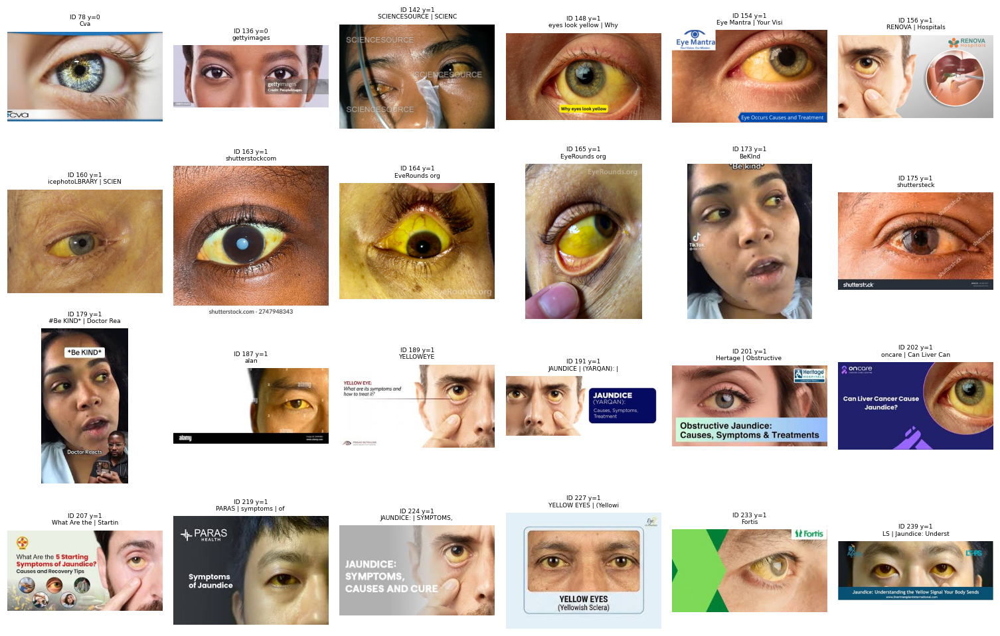

After removing images with overlaid text: 289 remain (32 removed)


In [7]:
TEXT_FOUND = {}
if CFG["OCR_FILTER"]:
    try:
        import easyocr
        reader = easyocr.Reader(["en"], gpu=(DEVICE == "cuda"), verbose=False)
        for i, im in zip(IDS, IMGS):
            res = reader.readtext(im)
            words = [t for (_, t, c) in res if c >= CFG["OCR_MIN_CONF"] and len(t.strip()) >= 2 and any(ch.isalpha() for ch in t)]
            if words: TEXT_FOUND[int(i)] = " | ".join(words)[:80]
    except Exception as e:
        fallback("OCR text filter", e)
flag = np.array([int(i) in TEXT_FOUND for i in IDS])
pd.DataFrame([{"id": k, "label": int(Y[list(IDS).index(k)]), "text": v} for k, v in TEXT_FOUND.items()]).to_csv(f'{CFG["OUT"]}/table_text_flagged.csv', index=False)
print(f"text found in {flag.sum()} images (jaundice {int(Y[flag].sum())}, normal {int((Y[flag] == 0).sum())})")
if flag.any():
    fl = np.where(flag)[0][:24]; c = 6; r = int(np.ceil(len(fl) / c))
    fig, ax = plt.subplots(r, c, figsize=(2.3 * c, 2.3 * r), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, k in zip(ax.ravel(), fl): a.imshow(IMGS[k]); a.set_title(f"ID {IDS[k]} y={Y[k]}\n{TEXT_FOUND[int(IDS[k])][:22]}", fontsize=6)
    savefig("fig02_text_flagged")
subset(~flag, "After removing images with overlaid text")

### 5b. Visually verified exclusions
Watermarks the OCR missed, collages and infants. **Look at the gallery**: if a tile is not a real problem, delete its ID from the lists in Section 1 and run again.

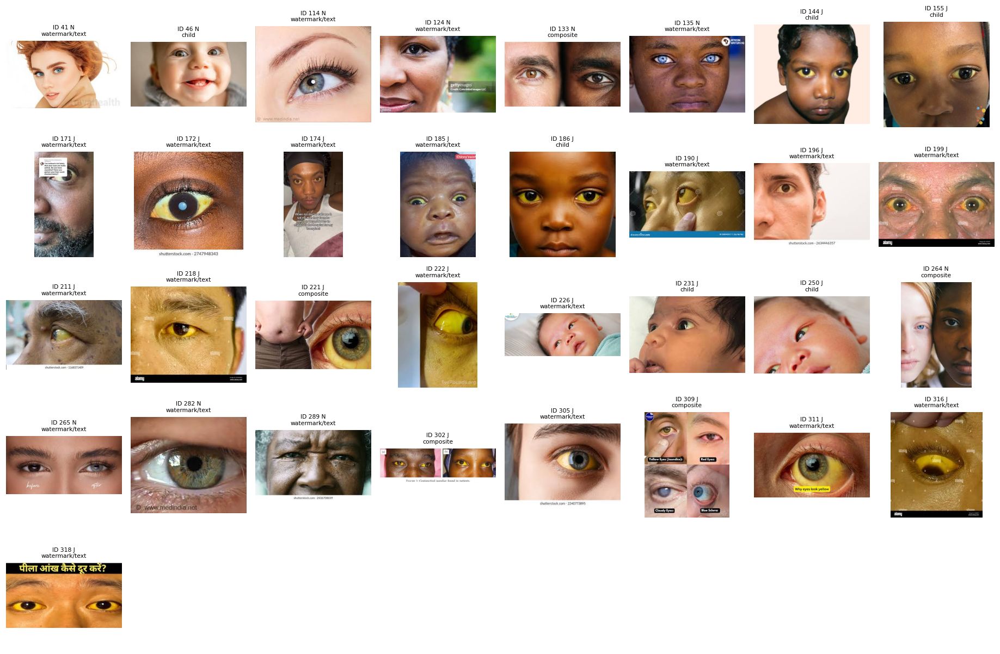

After removing watermark/text images (visual check): 267 remain (22 removed)
After removing composite images (visual check): 262 remain (5 removed)
After removing child images (visual check): 256 remain (6 removed)
finger/glove images kept for training, used in a sensitivity analysis: 24


In [8]:
USE_LISTS = CFG["DATA_SOURCE"] == "hf" and CFG["HF_ID"] == CFG["MANUAL_LISTS_FOR"]
EXCL = {}
if USE_LISTS:
    for reason, key in [("watermark/text", "EXCLUDE_WATERMARK"), ("composite", "EXCLUDE_COMPOSITE"), ("child", "EXCLUDE_CHILD")]:
        for i in CFG[key]: EXCL.setdefault(int(i), reason)
for i in CFG["EXCLUDE_IDS"]: EXCL.setdefault(int(i), "user")
hit = np.array([int(i) in EXCL for i in IDS])
if hit.any():
    k_ = np.where(hit)[0]; c = 8; r = int(np.ceil(len(k_) / c))
    fig, ax = plt.subplots(r, c, figsize=(2.1 * c, 2.2 * r), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, k in zip(ax.ravel(), k_): a.imshow(IMGS[k]); a.set_title(f"ID {IDS[k]} {'J' if Y[k] else 'N'}\n{EXCL[int(IDS[k])]}", fontsize=7)
    savefig("fig02b_manual_exclusions")
pd.DataFrame([{"id": int(i), "label": int(y), "reason": EXCL[int(i)]} for i, y in zip(IDS, Y) if int(i) in EXCL]).to_csv(f'{CFG["OUT"]}/table_manual_exclusions.csv', index=False)
for reason in ["watermark/text", "composite", "child", "user"]:
    m_ = np.array([EXCL.get(int(i)) == reason for i in IDS])
    if m_.any(): subset(~m_, f"After removing {reason} images (visual check)")
FINGER = np.array([USE_LISTS and int(i) in set(CFG["FINGER_IDS"]) for i in IDS])
print(f"finger/glove images kept for training, used in a sensitivity analysis: {FINGER.sum()}")

## 6. Sclera and eye-region segmentation

**Two sources, used automatically:**
1. **Manual polygons (recommended for the paper).** Run the next cell once: it writes `annotate_images.zip`. Upload those images to **https://www.makesense.ai** → *Object Detection* → create label `sclera` → draw a **polygon around the visible white of the eye** (one polygon per side of the iris is fine; both eyes if visible) → *Actions → Export Annotations → COCO JSON*. Upload the JSON to Colab as `/content/sclera_coco.json` and **Run all** again.
2. **CLIPSeg** (text-prompted segmentation) for every image without a manual polygon.

The eye-region crop used by all models is the sclera bounding box enlarged around the eye.

In [9]:
ANN_DIR = "/content/annotate_images" if os.path.isdir("/content") else f'{CFG["OUT"]}/annotate_images'
os.makedirs(ANN_DIR, exist_ok=True)
for i, im in zip(IDS, IMGS):
    p = f"{ANN_DIR}/img_{i:04d}.png"
    if not os.path.exists(p): Image.fromarray(im).save(p)
with zipfile.ZipFile(ANN_DIR + ".zip", "w") as z:
    for f in sorted(os.listdir(ANN_DIR)): z.write(f"{ANN_DIR}/{f}", f)
print(f"{len(IDS)} images written to {ANN_DIR}.zip  (file name = img_<ID>.png)")

256 images written to /content/annotate_images.zip  (file name = img_<ID>.png)


In [10]:
def load_coco_masks(path, ids, imgs):
    if not path or not os.path.exists(path): return {}
    coco = json.load(open(path)); by_img = {}
    for a in coco.get("annotations", []): by_img.setdefault(a["image_id"], []).append(a)
    out = {}
    id2im = {int(i): im for i, im in zip(ids, imgs)}
    for info in coco.get("images", []):
        name = os.path.basename(info["file_name"])
        if not name.startswith("img_"): continue
        try: iid = int(name[4:8])
        except ValueError: continue
        if iid not in id2im or info["id"] not in by_img: continue
        im = id2im[iid]; h, w = im.shape[:2]
        sx, sy = w / info.get("width", w), h / info.get("height", h)
        m = np.zeros((h, w), np.uint8)
        for a in by_img[info["id"]]:
            segs = a.get("segmentation") or []
            if isinstance(segs, list) and segs:
                for s in segs:
                    pts = np.array(s, np.float32).reshape(-1, 2) * [sx, sy]
                    cv2.fillPoly(m, [pts.round().astype(np.int32)], 1)
            elif a.get("bbox"):
                x, y, bw, bh = a["bbox"]; m[int(y * sy):int((y + bh) * sy), int(x * sx):int((x + bw) * sx)] = 1
        out[iid] = refine_sclera(im, m.astype(bool))
    return out

def refine_sclera(im, region):
    # remove iris / pupil / lashes inside a drawn region: drop the dark mode if the region is clearly bimodal
    if region.sum() < 30: return region
    L = cv2.cvtColor(im, cv2.COLOR_RGB2LAB)[..., 0]
    vals = L[region].reshape(-1, 1).astype(np.uint8)
    thr, _ = cv2.threshold(vals, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    dark = region & (L <= thr)
    m = region & ~dark if 0.12 < dark.sum() / region.sum() < 0.6 else region
    m &= ~(im.min(-1) >= 250)                                      # specular highlights
    if CFG["IRIS_HUE_FILTER"]:                                     # the sclera is never blue / green / purple
        hsv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV); hdeg = hsv[..., 0].astype(np.int32) * 2
        m &= ~(((hdeg >= 80) & (hdeg < 300)) & (hsv[..., 1] >= 40))
    return m if m.sum() >= 30 else region

MANUAL = load_coco_masks(CFG["SCLERA_COCO"], IDS, IMGS)
print(f"manual sclera polygons found for {len(MANUAL)} / {len(IDS)} images")

# ---------- CLIPSeg for the rest ----------
_CLIPSEG = None
def clipseg_heat(im, prompts):
    global _CLIPSEG
    if _CLIPSEG == "failed": raise RuntimeError("CLIPSeg unavailable")
    if _CLIPSEG is None:
      try:
        from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation
        _CLIPSEG = (CLIPSegProcessor.from_pretrained(CFG["SEG_MODEL"]),
                    CLIPSegForImageSegmentation.from_pretrained(CFG["SEG_MODEL"]).to(DEVICE).eval())
      except Exception:
        _CLIPSEG = "failed"; raise
    proc, net = _CLIPSEG
    x = proc(text=prompts, images=[Image.fromarray(im)] * len(prompts), padding=True, return_tensors="pt").to(DEVICE)
    with torch.no_grad(): lg = net(**x).logits
    hm = torch.sigmoid(lg).reshape(len(prompts), *lg.shape[-2:]).mean(0).cpu().numpy()
    return cv2.resize(hm, (im.shape[1], im.shape[0]))

def _largest(m, k=2, min_frac=0.15):
    n, lab, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), 8)
    if n <= 1: return m
    areas = st[1:, cv2.CC_STAT_AREA]; order = np.argsort(-areas)[:k]
    keep = [o + 1 for o in order if areas[o] >= min_frac * areas.max()]
    return np.isin(lab, keep)

def heuristic_sclera(im):  # TEST-ONLY fallback (used only when ALLOW_FALLBACK=True and CLIPSeg is unavailable)
    lab = cv2.cvtColor(im, cv2.COLOR_RGB2LAB).astype(np.float32); L, a = lab[..., 0], lab[..., 1]
    return _largest((L >= np.percentile(L, 80)) & (a <= np.percentile(a, 50)), 2)

K5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
def iris_region(im):
    try: ir = clipseg_heat(im, ["the iris of an eye", "the coloured iris and pupil of an eye"])
    except Exception as e: fallback("CLIPSeg iris", e); return None
    return ir >= max(0.3, 0.6 * ir.max())

def auto_sclera(im, iris=None):
    try:
        eye = clipseg_heat(im, ["an eye", "a human eye"])
        scl = clipseg_heat(im, ["the white of the eye", "white sclera of an eye"])
    except Exception as e:
        fallback("CLIPSeg segmentation", e); return refine_sclera(im, heuristic_sclera(im))
    eye_r = eye >= max(0.25, 0.5 * eye.max())
    eye_r = cv2.dilate(eye_r.astype(np.uint8), K5, iterations=3).astype(bool)
    cand = (scl >= max(0.2, 0.5 * scl.max())) & eye_r
    cand = cv2.morphologyEx(cand.astype(np.uint8), cv2.MORPH_OPEN, K5).astype(bool)
    cand = _largest(cand, 4, 0.1)
    if cand.sum() < 30: cand = eye_r
    if iris is not None and (cand & iris).sum() < 0.7 * max(1, cand.sum()):   # guard: never let the iris prompt erase the sclera
        cand = cand & ~iris
    return refine_sclera(im, cand)

def eye_box(im, m, pad_x=0.45, pad_y=1.0):
    h, w = im.shape[:2]; ys, xs = np.where(m)
    if len(ys) < 30: return (w // 6, h // 6, 5 * w // 6, 5 * h // 6)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max(); bw, bh = x1 - x0 + 1, y1 - y0 + 1
    bh_e = max(bh, 0.45 * bw)                               # an eye is roughly 2:1, so pad short sclera boxes
    cy = (y0 + y1) / 2
    return (int(max(0, x0 - pad_x * bw)), int(max(0, cy - (0.5 + pad_y) * bh_e)), int(min(w, x1 + pad_x * bw)), int(min(h, cy + (0.5 + pad_y) * bh_e)))
def crop(im, b): return im[b[1]:b[3], b[0]:b[2]]
def tight_box(im, m, pad=0.1):
    h, w = im.shape[:2]; ys, xs = np.where(m)
    if len(ys) < 30: return (w // 4, h // 4, 3 * w // 4, 3 * h // 4)
    py, px = int((ys.max() - ys.min()) * pad) + 2, int((xs.max() - xs.min()) * pad) + 2
    return (max(0, xs.min() - px), max(0, ys.min() - py), min(w, xs.max() + px), min(h, ys.max() + py))

def iris_colour(im, iris, scl):
    # light (blue / green / grey) vs dark (brown / black) iris, from CLIPSeg iris pixels outside the sclera and pupil
    if iris is None: return "unknown"
    px = im[iris & ~scl]
    if len(px) < 30: return "unknown"
    lab = _cv(px, cv2.COLOR_RGB2LAB); hsv = _cv(px, cv2.COLOR_RGB2HSV)
    keep = (lab[:, 0] * 100 / 255 > 20) & (px.min(1) < 245)               # drop pupil and highlights
    if keep.sum() < 20: return "unknown"
    h, s_, L = np.median(hsv[keep, 0]) * 2, np.median(hsv[keep, 1]), np.median(lab[keep, 0]) * 100 / 255
    return "light" if ((s_ >= 40 and 80 <= h < 300) or (L >= 55 and s_ < 40)) else "dark"
def _cv(px, code): return cv2.cvtColor(px.reshape(-1, 1, 3), code).reshape(-1, 3).astype(np.float32)

t0 = time.time(); MASKS, SEG_SRC, IRIS, IRIS_COL, RM_IRIS = [], [], [], [], []
for i, im in zip(IDS, IMGS):
    ir = iris_region(im); IRIS.append(ir)
    if int(i) in MANUAL: MASKS.append(MANUAL[int(i)]); SEG_SRC.append("manual")
    else: MASKS.append(auto_sclera(im, ir)); SEG_SRC.append("auto")
    IRIS_COL.append(iris_colour(im, ir, MASKS[-1]))
SEG_SRC, IRIS_COL = np.array(SEG_SRC), np.array(IRIS_COL)
print(pd.crosstab(IRIS_COL, np.where(Y == 1, "jaundice", "normal")))
BOXES = [eye_box(im, m) for im, m in zip(IMGS, MASKS)]
print(f"segmentation done in {time.time() - t0:.0f}s | manual {(SEG_SRC == 'manual').sum()} | auto {(SEG_SRC == 'auto').sum()}")

manual sclera polygons found for 0 / 256 images


preprocessor_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.73k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/974 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  603MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/462 [00:00<?, ?it/s]

col_0    jaundice  normal
row_0                    
dark           82      67
light           7      82
unknown         3      15
segmentation done in 91s | manual 0 | auto 256


### 6b. Mask quality control — **look at every page before trusting any result**
Each tile shows the sclera mask (cyan) and the eye crop box (yellow). Write the IDs of clearly wrong masks into `CFG["EXCLUDE_IDS"]` (or, better, annotate them manually) and run again. The QC table flags masks that are tiny or cover too much of the eye crop.

QC flags: 5 images (see table_mask_qc.csv)


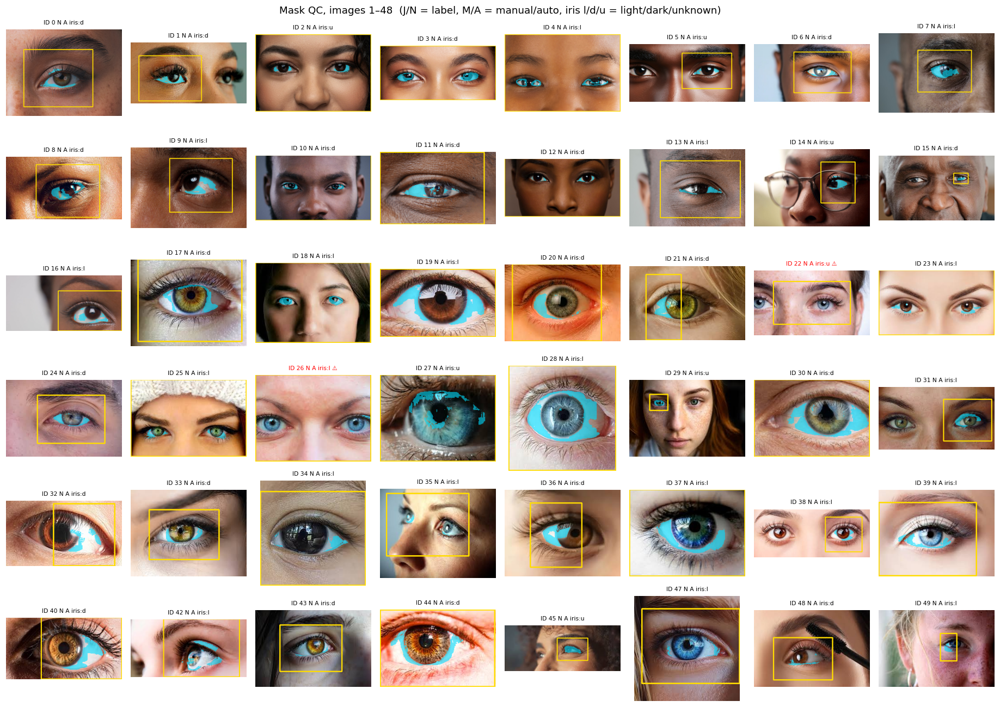

all QC pages saved in /content/results_v3/figures/qc/
After removing failed / excluded masks (final analysis set): 253 remain (3 removed)


,Step,Images,Jaundice,Normal
0,Images loaded,321,145,176
1,After removing near-duplicates with conflictin...,321,145,176
2,After removing images with overlaid text,289,115,174
3,After removing watermark/text images (visual c...,267,100,167
4,After removing composite images (visual check),262,97,165
5,After removing child images (visual check),256,92,164
6,After removing failed / excluded masks (final ...,253,90,163


In [11]:
qc = []
for i, im, m, b, s in zip(IDS, IMGS, MASKS, BOXES, SEG_SRC):
    area = m.sum(); box_area = max(1, (b[2] - b[0]) * (b[3] - b[1]))
    h, w = m.shape; e = max(2, int(0.03 * min(h, w)))
    edge = np.zeros_like(m); edge[:e] = edge[-e:] = True; edge[:, :e] = edge[:, -e:] = True
    on_edge = (m & edge).sum() / max(1, area)            # a real sclera almost never runs along the photo border
    qc.append({"id": int(i), "seg": s, "mask_px": int(area), "mask_frac_of_crop": area / box_area, "mask_on_image_border": on_edge,
               "flag": bool(area < 30 or area / box_area > 0.6 or on_edge > 0.10)})
QC = pd.DataFrame(qc); QC.to_csv(f'{CFG["OUT"]}/table_mask_qc.csv', index=False)
print(f"QC flags: {QC.flag.sum()} images (see table_mask_qc.csv)")

def overlay(im, m, b):
    o = im.copy(); o[m] = (0.4 * o[m] + 0.6 * np.array([0, 220, 255])).astype(np.uint8)
    cv2.rectangle(o, (b[0], b[1]), (b[2] - 1, b[3] - 1), (255, 220, 0), max(2, im.shape[1] // 150)); return o
PER = 48
for p0 in range(0, len(IMGS), PER):
    idx = list(range(p0, min(len(IMGS), p0 + PER))); c = 8; r = int(np.ceil(len(idx) / c))
    fig, ax = plt.subplots(r, c, figsize=(2.1 * c, 2.0 * r), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, k in zip(ax.ravel(), idx):
        a.imshow(overlay(IMGS[k], MASKS[k], BOXES[k]))
        a.set_title(f"ID {IDS[k]} {'J' if Y[k] else 'N'} {SEG_SRC[k][0].upper()} iris:{IRIS_COL[k][0]}{' ⚠' if QC.flag[k] else ''}", fontsize=7, color="red" if QC.flag[k] else "black")
    fig.suptitle(f"Mask QC, images {p0 + 1}–{idx[-1] + 1}  (J/N = label, M/A = manual/auto, iris l/d/u = light/dark/unknown)")
    savefig(f"qc/qc_masks_page{p0 // PER + 1:02d}", show=(p0 == 0))
print(f"all QC pages saved in {FIG}/qc/")

drop = np.isin(IDS, CFG["EXCLUDE_IDS"]) | (QC.mask_px.values < 30)
keepm = ~drop
MASKS = [m for m, k in zip(MASKS, keepm) if k]; BOXES = [b for b, k in zip(BOXES, keepm) if k]; SEG_SRC = SEG_SRC[keepm]
IRIS_COL = IRIS_COL[keepm]; FINGER = FINGER[keepm]
subset(keepm, "After removing failed / excluded masks (final analysis set)")
GROUPS = np.unique([GROUP_OF_ID[int(i)] for i in IDS], return_inverse=True)[1]
N = len(Y)

ECROP = [crop(im, b) for im, b in zip(IMGS, BOXES)]                         # eye-region crop (all models)
STIGHT = [crop(im, tight_box(im, m)) for im, m in zip(IMGS, MASKS)]        # tight sclera crop (B4)
def masked(im, m): o = im.copy(); o[~m] = 128; return o
SMASK = [crop(masked(im, m), tight_box(im, m)) for im, m in zip(IMGS, MASKS)]  # sclera-only pixels (SGHF stream 3)

pd.DataFrame({"id": IDS, "label": Y, "iris_colour": IRIS_COL, "finger_or_glove": FINGER}).to_csv(f'{CFG["OUT"]}/table_image_attributes.csv', index=False)
FLOWDF = pd.DataFrame(FLOW, columns=["Step", "Images", "Jaundice", "Normal"])
FLOWDF.to_csv(f'{CFG["OUT"]}/table_data_flow.csv', index=False); FLOWDF

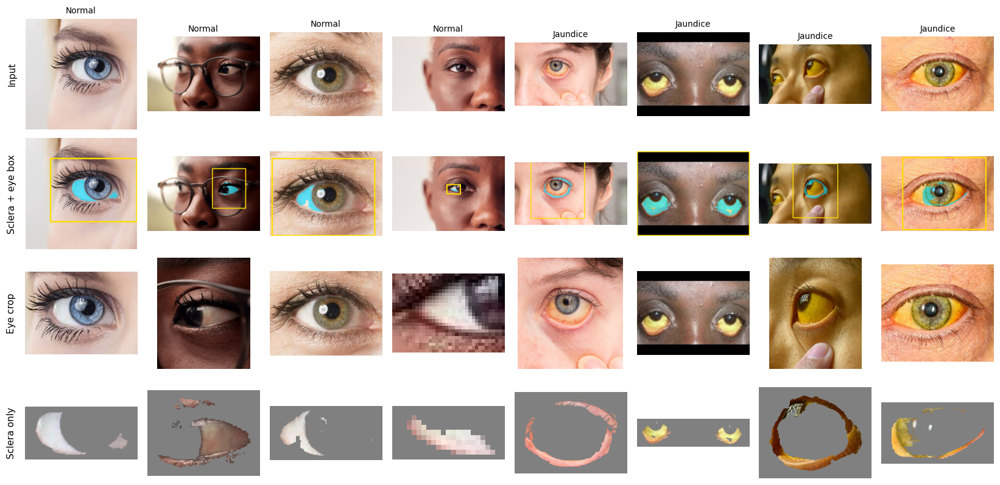

In [12]:
rng = np.random.default_rng(CFG["SEED"])
pick = np.r_[rng.choice(np.where(Y == 0)[0], 4, False), rng.choice(np.where(Y == 1)[0], 4, False)]
fig, ax = plt.subplots(4, 8, figsize=(15, 7.5))
for c, k in enumerate(pick):
    for r, (img, t) in enumerate([(IMGS[k], "Input"), (overlay(IMGS[k], MASKS[k], BOXES[k]), "Sclera + eye box"),
                                  (ECROP[k], "Eye crop"), (SMASK[k], "Sclera only")]):
        ax[r, c].imshow(img); ax[r, c].axis("off")
        if c == 0: ax[r, c].text(-0.08, 0.5, t, transform=ax[r, c].transAxes, rotation=90, va="center", ha="right")
    ax[0, c].set_title(["Normal", "Jaundice"][Y[k]], fontsize=9)
savefig("fig03_preprocessing_pipeline")

## 7. Colour biomarkers of the sclera

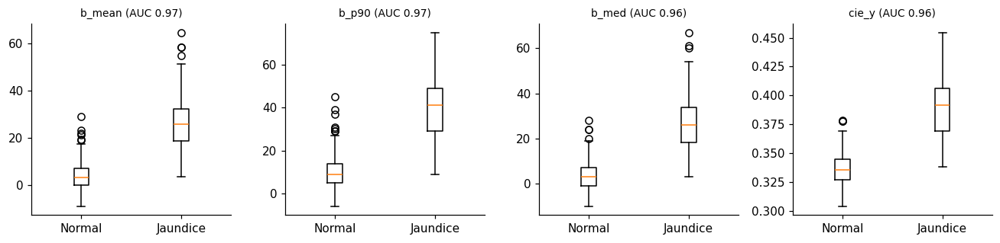

,feature,mean_normal,mean_jaundice,AUC_univariate,p_MannWhitney
24,b_mean,4.017000,27.243000,0.971,0.0
26,b_p90,10.383000,40.897999,0.968,0.0
25,b_med,3.525000,27.461000,0.964,0.0
33,cie_y,0.336000,0.390000,0.964,0.0
31,G_over_B,1.030000,1.759000,0.954,0.0
29,yellow_bL,0.099000,0.498000,0.947,0.0
30,R_over_B,1.156000,2.351000,0.935,0.0
13,S_med,40.776001,120.261002,0.930,0.0
12,S_mean,45.994999,119.317001,0.927,0.0
32,cie_x,0.339000,0.402000,0.913,0.0


In [13]:
def _conv(px, code): return cv2.cvtColor(px.reshape(-1, 1, 3), code).reshape(-1, 3).astype(np.float32)
HC_NAMES = [f"{c}_{s}" for c in ["R", "G", "B", "H", "S", "V", "L", "a", "b"] for s in ["mean", "med", "p90"]] + \
           ["chroma_r", "chroma_g", "yellow_bL", "R_over_B", "G_over_B", "cie_x", "cie_y"]
def colour_features(im, m):
    px = im[m] if m.sum() >= 30 else im.reshape(-1, 3); f = px.astype(np.float32)
    hsv = _conv(px, cv2.COLOR_RGB2HSV); hsv[:, 0] *= 2
    lab = _conv(px, cv2.COLOR_RGB2LAB); lab[:, 0] *= 100 / 255; lab[:, 1:] -= 128
    out = []
    for ch in [f[:, 0], f[:, 1], f[:, 2], hsv[:, 0], hsv[:, 1], hsv[:, 2], lab[:, 0], lab[:, 1], lab[:, 2]]:
        out += [ch.mean(), np.median(ch), np.percentile(ch, 90)]
    s = f.sum(1) + 1e-6
    lin = np.where(f / 255 <= 0.04045, f / 255 / 12.92, ((f / 255 + 0.055) / 1.055) ** 2.4)
    xyz = lin @ np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]]).T; xs = xyz.sum(1) + 1e-6
    out += [(f[:, 0] / s).mean(), (f[:, 1] / s).mean(), (lab[:, 2] / (lab[:, 0] + 1)).mean(),
            np.median(f[:, 0] / (f[:, 2] + 1)), np.median(f[:, 1] / (f[:, 2] + 1)), (xyz[:, 0] / xs).mean(), (xyz[:, 1] / xs).mean()]
    return np.array(out, np.float32)
def max_hue_degree(im, m):
    # open approximation of Kihara et al.'s proprietary ABHB maximum hue degree: 95th pct of HSL hue of warm sclera pixels
    px = im[m] if m.sum() >= 30 else im.reshape(-1, 3); h = _conv(px, cv2.COLOR_RGB2HLS)[:, 0] * 2; warm = h[h <= 90]
    return np.float32(np.percentile(warm, 95) if len(warm) >= 10 else np.median(h))
def grey_world(im):
    f = im.astype(np.float32); mu = f.reshape(-1, 3).mean(0); return np.clip(f * (mu.mean() / (mu + 1e-6)), 0, 255).astype(np.uint8)

HC = np.stack([colour_features(im, m) for im, m in zip(IMGS, MASKS)])
HC_CC = np.stack([colour_features(grey_world(crop(im, b)), crop(m, b)) for im, m, b in zip(IMGS, MASKS, BOXES)])
MHD = np.array([max_hue_degree(im, m) for im, m in zip(IMGS, MASKS)]).reshape(-1, 1)
eff = pd.DataFrame({"feature": HC_NAMES, "mean_normal": HC[Y == 0].mean(0), "mean_jaundice": HC[Y == 1].mean(0),
                    "AUC_univariate": [roc_auc_score(Y, HC[:, k]) for k in range(HC.shape[1])],
                    "p_MannWhitney": [stats.mannwhitneyu(HC[Y == 1, k], HC[Y == 0, k]).pvalue for k in range(HC.shape[1])]})
eff = eff.sort_values("AUC_univariate", key=lambda s: -abs(s - 0.5)); eff.to_csv(f'{CFG["OUT"]}/table_biomarker_univariate.csv', index=False)

top = eff.feature.head(4).tolist()
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, f_ in zip(ax, top):
    k = HC_NAMES.index(f_); a.boxplot([HC[Y == 0, k], HC[Y == 1, k]]); a.set_xticks([1, 2], ["Normal", "Jaundice"])
    a.set_title(f"{f_} (AUC {roc_auc_score(Y, HC[:, k]):.2f})", fontsize=9)
savefig("fig04_top_biomarkers")
eff.head(10).round(3)

## 8. Frozen deep embeddings (no labels used → no leakage)

In [14]:
NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
TF_EVAL = T.Compose([T.ToPILImage(), T.Resize((CFG["IMG"], CFG["IMG"])), T.ToTensor(), NORM])
def build_extractor():
    if CFG["BACKBONE"].startswith("dinov2"):
        try: return torch.hub.load("facebookresearch/dinov2", CFG["BACKBONE"]).eval().to(DEVICE), CFG["BACKBONE"]
        except Exception as e: fallback("DINOv2 backbone", e)
    m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1 if CFG["PRETRAINED"] else None)
    m.classifier = nn.Identity(); return m.eval().to(DEVICE), "efficientnet_b0"
EXTRACTOR, BACKBONE_USED = build_extractor(); print("SGHF backbone:", BACKBONE_USED)
@torch.no_grad()
def embed(img_list, bs=32):
    out = []
    for k in range(0, len(img_list), bs):
        x = torch.stack([TF_EVAL(im) for im in img_list[k:k + bs]]).to(DEVICE)
        out.append(((EXTRACTOR(x) + EXTRACTOR(torch.flip(x, dims=[3]))) / 2).cpu().numpy())
    return np.concatenate(out).astype(np.float32)
t0 = time.time()
E_EYE, E_SCL = embed(ECROP), embed(SMASK)
E_EYE_CC, E_SCL_CC = embed([grey_world(c) for c in ECROP]), embed([grey_world(c) for c in SMASK])
print("embeddings", E_EYE.shape, f"{time.time() - t0:.0f}s")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 274MB/s]


SGHF backbone: dinov2_vits14
embeddings (253, 384) 12s


## 9. Models
All six models use the **eye-region crop** (or the sclera inside it) and the **same folds**. Scaling, PCA and hyper-parameter search happen inside the training fold; CNN early stopping uses an inner validation split from training groups only.

| ID | Re-implementation | Input |
|---|---|---|
| B1 | Mariakakis 2017: mean sclera colour (RGB/HSV/Lab) + Random Forest | sclera pixels |
| B2 | Kihara 2023: maximum hue degree → logistic regression | sclera pixels |
| B3 | Althnian 2021: VGG16 transfer learning (fine-tuned) | eye crop |
| B4 | Park 2021: CNN on sclera image (ResNet-50, fine-tuned) | tight sclera crop |
| B5 | Seok 2025: colour features + XGBoost | sclera pixels |
| P | **SGHF**: sclera biomarkers ⊕ PCA(eye-crop embedding) ⊕ PCA(sclera-only embedding) → tuned LR/SVM | all three |

In [15]:
MODELS = ["B1 Mariakakis2017 RF", "B2 Kihara2023 MHD", "B3 Althnian2021 VGG16",
          "B4 Park2021 ResNet50", "B5 Seok2025 XGBoost", "P  SGHF (proposed)"]
PROP = MODELS[-1]
B1_COLS = [HC_NAMES.index(f"{c}_mean") for c in ["R", "G", "B", "H", "S", "V", "L", "a", "b"]]
def fit_b1(Xtr, ytr, Xte, seed):
    return RandomForestClassifier(500, min_samples_leaf=2, class_weight="balanced", random_state=seed, n_jobs=-1).fit(Xtr[:, B1_COLS], ytr).predict_proba(Xte[:, B1_COLS])[:, 1]
def fit_b2(Mtr, ytr, Mte):
    return Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(class_weight="balanced", max_iter=2000))]).fit(Mtr, ytr).predict_proba(Mte)[:, 1]
def fit_b5(Xtr, ytr, Xte, seed):
    if HAS_XGB:
        m = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=(ytr == 0).sum() / max(1, (ytr == 1).sum()), eval_metric="logloss", random_state=seed, n_jobs=2, verbosity=0)
    else: m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, class_weight="balanced", random_state=seed)
    return m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def make_sghf(dims, seed, use=("hc", "w", "s"), n_fit=10**6):
    blocks, i0 = [], 0
    for name, n_ in zip(("hc", "w", "s"), dims):
        idx = list(range(i0, i0 + n_)); i0 += n_
        if name not in use: continue
        blocks.append((name, StandardScaler(), idx) if name == "hc" else
                      (name, Pipeline([("sc", StandardScaler()), ("pca", PCA(16, random_state=seed))]), idx))
    pipe = Pipeline([("pre", ColumnTransformer(blocks)), ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
    n_inner = int(n_fit * 2 / 3) - 1                      # PCA size must stay below the inner-training sample count
    pca_grid = [v for v in [16, 48, 96] if v < n_inner] or [max(2, min(8, n_inner))]
    pg = {f"pre__{b}__pca__n_components": pca_grid for b in ("w", "s") if b in use}
    grid = [{**pg, "clf": [LogisticRegression(class_weight="balanced", max_iter=5000)], "clf__C": [0.003, 0.03, 0.3, 3, 30, 300, 3000]},
            {**pg, "clf": [SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=seed)],
             "clf__C": [0.5, 2, 8, 32, 128, 512], "clf__gamma": ["scale"]}]
    return GridSearchCV(pipe, grid, scoring="roc_auc", cv=StratifiedGroupKFold(3, shuffle=True, random_state=seed), n_jobs=-1, refit=True, error_score=np.nan)
def fit_sghf(Xtr, ytr, gtr, Xte, seed, use=("hc", "w", "s")):
    gs_ = make_sghf(DIMS, seed, use, n_fit=len(Xtr)).fit(Xtr, ytr, groups=gtr); return gs_.predict_proba(Xte)[:, 1], gs_.best_params_
DIMS = (HC.shape[1], E_EYE.shape[1], E_SCL.shape[1])
X_SGHF, X_SGHF_CC = np.hstack([HC, E_EYE, E_SCL]), np.hstack([HC_CC, E_EYE_CC, E_SCL_CC])

In [16]:
TF_TRAIN = T.Compose([T.ToPILImage(), T.RandomResizedCrop(CFG["IMG"], scale=(0.75, 1.0), ratio=(0.8, 1.25)),
                      T.RandomHorizontalFlip(), T.RandomRotation(10), T.ColorJitter(brightness=0.1, contrast=0.1),
                      T.ToTensor(), NORM])                       # no hue/saturation jitter: yellow is the signal
class ImgDS(torch.utils.data.Dataset):
    def __init__(s, imgs, y, tf): s.imgs, s.y, s.tf = imgs, y, tf
    def __len__(s): return len(s.imgs)
    def __getitem__(s, i): return s.tf(s.imgs[i]), torch.tensor(float(s.y[i]))
def build_cnn(arch):
    if arch == "vgg16":
        m = tvm.vgg16(weights=tvm.VGG16_Weights.IMAGENET1K_V1 if CFG["PRETRAINED"] else None); m.classifier[6] = nn.Linear(4096, 1)
    else:
        m = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2 if CFG["PRETRAINED"] else None); m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(DEVICE)
@torch.no_grad()
def predict_cnn(m, imgs):
    m.eval(); out = []
    for x, _ in torch.utils.data.DataLoader(ImgDS(imgs, np.zeros(len(imgs)), TF_EVAL), batch_size=32):
        x = x.to(DEVICE); out.append(((torch.sigmoid(m(x)) + torch.sigmoid(m(torch.flip(x, dims=[3])))) / 2).squeeze(1).cpu().numpy())
    return np.concatenate(out)
def train_cnn(arch, imgs, y, groups, seed):
    seed_all(seed)
    for k in range(10):
        tr, va = next(GroupShuffleSplit(1, test_size=0.15, random_state=seed + k).split(imgs, y, groups))
        if len(set(y[va])) == 2: break
    m = build_cnn(arch)
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(y[tr] == 0).sum() / max(1, (y[tr] == 1).sum())], device=DEVICE))
    opt = torch.optim.AdamW(m.parameters(), lr=CFG["LR"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"])
    g = torch.Generator(); g.manual_seed(seed)
    dl = torch.utils.data.DataLoader(ImgDS([imgs[i] for i in tr], y[tr], TF_TRAIN), batch_size=CFG["BATCH"], shuffle=True, generator=g, drop_last=len(tr) > CFG["BATCH"])
    best, state, wait = np.inf, None, 0
    for ep in range(CFG["EPOCHS"]):
        m.train()
        for x, t in dl:
            x, t = x.to(DEVICE), t.to(DEVICE); opt.zero_grad(); lossf(m(x).squeeze(1), t).backward(); opt.step()
        sched.step()
        pv = np.clip(predict_cnn(m, [imgs[i] for i in va]), 1e-6, 1 - 1e-6)
        vl = -np.mean(y[va] * np.log(pv) + (1 - y[va]) * np.log(1 - pv))
        if vl < best - 1e-4: best, wait, state = vl, 0, {k_: v.detach().clone() for k_, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG["PATIENCE"]: break
    m.load_state_dict(state); return m

## 10. Repeated stratified group k-fold cross-validation

In [ ]:
R, K = CFG["N_REPEATS"], CFG["N_SPLITS"]
OOF = {m: np.zeros((R, N)) for m in MODELS}; FOLD_ROWS, BEST_PARAMS = [], []; FOLD_ID = np.zeros((R, N), int)
def splits(seed): return list(StratifiedGroupKFold(K, shuffle=True, random_state=seed).split(np.zeros(N), Y, GROUPS))
t_start = time.time()
for r in range(R):
    seed = CFG["SEED"] + r
    for f, (tr, te) in enumerate(splits(seed)):
        FOLD_ID[r, te] = f; ytr = Y[tr]; P = {}
        P[MODELS[0]] = fit_b1(HC[tr], ytr, HC[te], seed)
        P[MODELS[1]] = fit_b2(MHD[tr], ytr, MHD[te])
        m3 = train_cnn("vgg16", [ECROP[i] for i in tr], ytr, GROUPS[tr], seed); P[MODELS[2]] = predict_cnn(m3, [ECROP[i] for i in te]); del m3
        m4 = train_cnn("resnet50", [STIGHT[i] for i in tr], ytr, GROUPS[tr], seed); P[MODELS[3]] = predict_cnn(m4, [STIGHT[i] for i in te]); del m4
        if DEVICE == "cuda": torch.cuda.empty_cache()
        P[MODELS[4]] = fit_b5(HC[tr], ytr, HC[te], seed)
        P[PROP], bp = fit_sghf(X_SGHF[tr], ytr, GROUPS[tr], X_SGHF[te], seed)
        BEST_PARAMS.append({"repeat": r, "fold": f, **{k: str(v).split("(")[0] if k == "clf" else str(v) for k, v in bp.items()}})
        for m, p in P.items():
            OOF[m][r, te] = p
            FOLD_ROWS.append({"repeat": r, "fold": f, "model": m, "n_train": len(tr), "n_test": len(te), "AUC": roc_auc_score(Y[te], p) if len(set(Y[te])) > 1 else np.nan})
        print(f"r{r + 1}/{R} f{f + 1}/{K} | " + " | ".join(f"{m.split()[0]} {FOLD_ROWS[-6 + k]['AUC']:.3f}" for k, m in enumerate(MODELS)) + f" | {time.time() - t_start:.0f}s")
FOLDS = pd.DataFrame(FOLD_ROWS); FOLDS.to_csv(f'{CFG["OUT"]}/table_per_fold_auc.csv', index=False)
BP = pd.DataFrame(BEST_PARAMS); BP.to_csv(f'{CFG["OUT"]}/table_sghf_selected_hyperparams.csv', index=False)
pd.DataFrame({"id": IDS, "source": SRC, "label": Y, "group": GROUPS, "seg": SEG_SRC, **{f"fold_r{r}": FOLD_ID[r] for r in range(R)},
              **{f"{m}__r{r}": OOF[m][r] for m in MODELS for r in range(R)}}).to_csv(f'{CFG["OUT"]}/oof_predictions.csv', index=False)
print("CV done in %.1f min" % ((time.time() - t_start) / 60))
print("SGHF selected settings (check none sit on the grid edge every time):"); print(BP.drop(columns=["repeat", "fold"]).value_counts().head(6))

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 84.8MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


r1/3 f1/5 | B1 0.980 | B2 0.503 | B3 1.000 | B4 0.953 | B5 0.981 | P 0.936 | 92s
r1/3 f2/5 | B1 0.963 | B2 0.533 | B3 0.960 | B4 0.938 | B5 0.950 | P 0.930 | 205s
r1/3 f3/5 | B1 0.951 | B2 0.574 | B3 1.000 | B4 0.969 | B5 0.969 | P 0.945 | 339s
r1/3 f4/5 | B1 0.982 | B2 0.559 | B3 0.956 | B4 0.950 | B5 0.983 | P 0.958 | 428s
r1/3 f5/5 | B1 0.977 | B2 0.402 | B3 1.000 | B4 0.967 | B5 0.953 | P 0.993 | 561s
r2/3 f1/5 | B1 0.956 | B2 0.492 | B3 0.970 | B4 0.884 | B5 0.956 | P 0.916 | 680s
r2/3 f2/5 | B1 0.968 | B2 0.598 | B3 1.000 | B4 0.923 | B5 0.983 | P 0.942 | 817s
r2/3 f3/5 | B1 0.972 | B2 0.487 | B3 1.000 | B4 0.989 | B5 0.960 | P 1.000 | 899s
r2/3 f4/5 | B1 0.934 | B2 0.442 | B3 1.000 | B4 0.947 | B5 0.954 | P 0.950 | 1031s
r2/3 f5/5 | B1 0.986 | B2 0.567 | B3 1.000 | B4 0.961 | B5 0.976 | P 0.997 | 1145s
r3/3 f1/5 | B1 0.980 | B2 0.523 | B3 1.000 | B4 0.978 | B5 0.975 | P 0.984 | 1275s
r3/3 f2/5 | B1 0.967 | B2 0.562 | B3 1.000 | B4 0.955 | B5 0.975 | P 0.994 | 1370s


## 11. Metrics, 95% CI, statistical tests

In [ ]:
def ece_score(y, p, bins=10):
    e = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, e) - 1, 0, bins - 1)
    return sum((idx == b).mean() * abs(p[idx == b].mean() - y[idx == b].mean()) for b in range(bins) if (idx == b).any())
def metrics(y, p, thr=CFG["THRESHOLD"]):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y, p), "Accuracy": accuracy_score(y, yh), "Sensitivity": tp / max(1, tp + fn),
            "Specificity": tn / max(1, tn + fp), "Precision": precision_score(y, yh, zero_division=0), "F1": f1_score(y, yh, zero_division=0),
            "MCC": matthews_corrcoef(y, yh), "Brier": brier_score_loss(y, p), "ECE": ece_score(y, p)}
def group_bootstrap(y, p, groups, fn, B=CFG["N_BOOT"], seed=CFG["SEED"]):
    rs = np.random.default_rng(seed); ug = np.unique(groups); by = {g: np.where(groups == g)[0] for g in ug}; v = []
    for _ in range(B):
        idx = np.concatenate([by[g] for g in rs.choice(ug, len(ug))])
        if len(set(y[idx])) == 2: v.append(fn(y[idx], p[idx]))
    return np.percentile(v, [2.5, 97.5])

P_AVG = {m: OOF[m].mean(0) for m in MODELS}; rows = []
for m in MODELS:
    rep = pd.DataFrame([metrics(Y, OOF[m][r]) for r in range(R)]); pooled = metrics(Y, P_AVG[m]); row = {"Model": m, "n": N}
    for k, v in pooled.items(): row[k] = v; row[k + "_sd_repeats"] = rep[k].std(ddof=1) if R > 1 else np.nan
    (row["AUC_CI_low"], row["AUC_CI_high"]) = group_bootstrap(Y, P_AVG[m], GROUPS, roc_auc_score)
    (row["Brier_CI_low"], row["Brier_CI_high"]) = group_bootstrap(Y, P_AVG[m], GROUPS, brier_score_loss)
    rows.append(row)
RES = pd.DataFrame(rows); RES.to_csv(f'{CFG["OUT"]}/table_main_results.csv', index=False)
nice = RES[["Model"]].copy()
nice["AUC (95% CI)"] = [f"{a:.3f} ({l:.3f}–{h:.3f})" for a, l, h in zip(RES.AUC, RES.AUC_CI_low, RES.AUC_CI_high)]
for k in ["Accuracy", "Sensitivity", "Specificity", "F1", "MCC"]: nice[k] = [f"{v:.3f}" for v in RES[k]]
nice["Brier (95% CI)"] = [f"{a:.3f} ({l:.3f}–{h:.3f})" for a, l, h in zip(RES.Brier, RES.Brier_CI_low, RES.Brier_CI_high)]
nice["ECE"] = [f"{v:.3f}" for v in RES.ECE]
nice.to_csv(f'{CFG["OUT"]}/table_main_results_formatted.csv', index=False)
try: open(f'{CFG["OUT"]}/table_main_results.tex', "w").write(nice.to_latex(index=False))
except Exception as e: print("LaTeX skipped:", e)
nice

In [ ]:
def _midrank(x):
    J = np.argsort(x); Z = x[J]; n = len(x); T_ = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and Z[j] == Z[i]: j += 1
        T_[i:j] = 0.5 * (i + j - 1) + 1; i = j
    o = np.empty(n); o[J] = T_; return o
def delong(y, p1, p2):
    m, n = (y == 1).sum(), (y == 0).sum()
    P = np.vstack([np.r_[p1[y == 1], p1[y == 0]], np.r_[p2[y == 1], p2[y == 0]]])
    tx = np.array([_midrank(r[:m]) for r in P]); ty = np.array([_midrank(r[m:]) for r in P]); tz = np.array([_midrank(r) for r in P])
    auc = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n
    S = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1 - (tz[:, m:] - ty) / m) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]; z = (auc[0] - auc[1]) / np.sqrt(var) if var > 0 else 0.0
    return auc[0] - auc[1], 2 * stats.norm.sf(abs(z))
def nadeau_bengio(a, b, ntr, nte):
    d = np.asarray(a) - np.asarray(b); k = len(d); v = d.var(ddof=1)
    if v == 0: return d.mean(), 1.0
    return d.mean(), 2 * stats.t.sf(abs(d.mean() / np.sqrt((1 / k + nte / ntr) * v)), k - 1)
def holm(p):
    p = np.asarray(p); o = np.argsort(p); a = np.empty_like(p); run = 0
    for r_, i in enumerate(o): run = max(run, (len(p) - r_) * p[i]); a[i] = min(1, run)
    return a
FA = FOLDS.pivot_table(index=["repeat", "fold"], columns="model", values="AUC")
tr_ = []
for m in MODELS[:-1]:
    dd, pd_ = delong(Y, P_AVG[PROP], P_AVG[m]); dn, pn = nadeau_bengio(FA[PROP].values, FA[m].values, FOLDS.n_train.mean(), FOLDS.n_test.mean())
    tr_.append({"Comparison": f"SGHF vs {m}", "dAUC_DeLong": dd, "p_DeLong": pd_, "dAUC_meanfold": dn, "p_NadeauBengio": pn})
TESTS = pd.DataFrame(tr_); TESTS["p_DeLong_Holm"] = holm(TESTS.p_DeLong); TESTS["p_NB_Holm"] = holm(TESTS.p_NadeauBengio)
TESTS.to_csv(f'{CFG["OUT"]}/table_statistical_tests.csv', index=False); TESTS.round(4)

## 11b. Confound analysis (eye colour, fingers/gloves)
The out-of-fold predictions are re-scored inside subgroups where the suspected confounder cannot explain the label. If AUC stays high in **dark-iris only** and **no finger/glove**, the models are reading sclera colour, not eye colour or hands.

In [ ]:
print("iris colour by class (final set):"); print(pd.crosstab(IRIS_COL, np.where(Y == 1, "jaundice", "normal"), margins=True))
SUBS = {"All images": np.ones(N, bool), "Dark iris only": IRIS_COL == "dark", "No finger / glove": ~FINGER,
        "Dark iris and no finger / glove": (IRIS_COL == "dark") & ~FINGER}
sg = []
for sname, msk in SUBS.items():
    ok = msk.sum() >= 20 and len(set(Y[msk])) == 2 and min((Y[msk] == 0).sum(), (Y[msk] == 1).sum()) >= 5
    for m in MODELS:
        row = {"Subgroup": sname, "n": int(msk.sum()), "n_jaundice": int(Y[msk].sum()), "Model": m}
        if ok:
            row["AUC"] = roc_auc_score(Y[msk], P_AVG[m][msk])
            row["AUC_CI_low"], row["AUC_CI_high"] = group_bootstrap(Y[msk], P_AVG[m][msk], GROUPS[msk], roc_auc_score)
        sg.append(row)
SUBG = pd.DataFrame(sg); SUBG.to_csv(f'{CFG["OUT"]}/table_subgroup_confounds.csv', index=False)
if "AUC" in SUBG:
    piv = SUBG.pivot(index="Model", columns="Subgroup", values="AUC")[list(SUBS)].reindex(MODELS)
    fig, ax = plt.subplots(figsize=(9, 3.8)); w_ = 0.2
    for j, sname in enumerate(SUBS):
        ax.barh(np.arange(len(MODELS)) + (j - 1.5) * w_, piv[sname], height=w_, label=f"{sname} (n={int(SUBS[sname].sum())})")
    ax.set_yticks(range(len(MODELS)), MODELS); ax.invert_yaxis(); ax.set_xlim(0.4, 1.0); ax.set_xlabel("AUC (out-of-fold)"); ax.legend(fontsize=7, loc="lower left")
    savefig("fig07b_subgroup_confounds")
    display(piv.round(3))

## 12. Figures

In [ ]:
COL = ["#8c8c8c", "#b07aa1", "#4e79a7", "#59a14f", "#f28e2b", "#d62728"]; LS = [":", "-.", "--", "--", "-.", "-"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for m, c, ls in zip(MODELS, COL, LS):
    fpr, tpr, _ = roc_curve(Y, P_AVG[m]); lw = 2.4 if m == PROP else 1.5
    ax[0].plot(fpr, tpr, ls, color=c, lw=lw, label=f"{m} ({RES.set_index('Model').loc[m, 'AUC']:.3f})")
    fp_, mp_ = calibration_curve(Y, P_AVG[m], n_bins=8, strategy="quantile"); ax[1].plot(mp_, fp_, ls, marker="o", ms=3, color=c, lw=lw, label=m)
for a in ax: a.plot([0, 1], [0, 1], color="#ccc", lw=1)
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (out-of-fold)"); ax[0].legend(fontsize=7.5, loc="lower right")
ax[1].set(xlabel="Mean predicted probability", ylabel="Observed fraction jaundiced", title="Calibration"); ax[1].legend(fontsize=7.5, loc="upper left")
savefig("fig05_roc_calibration")

fig, ax = plt.subplots(2, 3, figsize=(11, 6.6))
for a, m in zip(ax.ravel(), MODELS):
    cm = confusion_matrix(Y, (P_AVG[m] >= CFG["THRESHOLD"]).astype(int), labels=[0, 1]); a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center", fontsize=12, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1], ["Normal", "Jaundice"]); a.set_yticks([0, 1], ["Normal", "Jaundice"]); a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(m, fontsize=9)
savefig("fig06_confusion_matrices")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
yy = np.arange(len(MODELS))[::-1]
ax[0].errorbar(RES.AUC, yy, xerr=[RES.AUC - RES.AUC_CI_low, RES.AUC_CI_high - RES.AUC], fmt="none", ecolor="#999", capsize=3)
ax[0].scatter(RES.AUC, yy, c=COL, s=60, zorder=3); ax[0].set_yticks(yy, MODELS); ax[0].set_xlabel("AUC (group-bootstrap 95% CI)")
ax[1].boxplot([FA[m].dropna().values for m in MODELS], vert=False); ax[1].set_yticks(range(1, 7), MODELS); ax[1].set_xlabel(f"Per-fold AUC ({R}×{K})")
savefig("fig07_auc_ci_and_folds")

## 13. Ablation of SGHF (same folds, same inner tuning)

In [22]:
VARIANTS = [("Sclera biomarkers only", X_SGHF, ("hc",)), ("Eye-crop embedding only", X_SGHF, ("w",)),
            ("Sclera-only embedding only", X_SGHF, ("s",)), ("Biomarkers + eye-crop emb.", X_SGHF, ("hc", "w")),
            ("Biomarkers + sclera emb.", X_SGHF, ("hc", "s")), ("Eye-crop + sclera emb.", X_SGHF, ("w", "s")),
            ("Full SGHF", X_SGHF, ("hc", "w", "s")), ("Full SGHF + grey-world colour constancy", X_SGHF_CC, ("hc", "w", "s"))]
abl = []
for name, X, use in VARIANTS:
    if name == "Full SGHF": Pm = OOF[PROP]
    else:
        Pm = np.zeros((R, N))
        for r in range(R):
            for tr, te in splits(CFG["SEED"] + r): Pm[r, te], _ = fit_sghf(X[tr], Y[tr], GROUPS[tr], X[te], CFG["SEED"] + r, use)
    lo, hi = group_bootstrap(Y, Pm.mean(0), GROUPS, roc_auc_score)
    abl.append({"Variant": name, "AUC": roc_auc_score(Y, Pm.mean(0)), "AUC_sd_repeats": np.std([roc_auc_score(Y, Pm[r]) for r in range(R)], ddof=1) if R > 1 else np.nan,
                "AUC_CI_low": lo, "AUC_CI_high": hi, "Brier": brier_score_loss(Y, Pm.mean(0))}); print(f"{name:40s} {abl[-1]['AUC']:.3f}")
ABL = pd.DataFrame(abl); ABL.to_csv(f'{CFG["OUT"]}/table_ablation.csv', index=False); ABL.round(3)

Sclera biomarkers only                   0.974
Eye-crop embedding only                  0.938
Sclera-only embedding only               0.921
Biomarkers + eye-crop emb.               0.976
Biomarkers + sclera emb.                 0.954
Eye-crop + sclera emb.                   0.957
Full SGHF                                0.967
Full SGHF + grey-world colour constancy  0.964


,Variant,AUC,AUC_sd_repeats,AUC_CI_low,AUC_CI_high,Brier
0,Sclera biomarkers only,0.974,0.003,0.955,0.989,0.062
1,Eye-crop embedding only,0.938,0.013,0.901,0.970,0.083
2,Sclera-only embedding only,0.921,0.015,0.875,0.958,0.094
3,Biomarkers + eye-crop emb.,0.976,0.009,0.953,0.993,0.048
4,Biomarkers + sclera emb.,0.954,0.016,0.925,0.979,0.073
5,Eye-crop + sclera emb.,0.957,0.013,0.925,0.982,0.069
6,Full SGHF,0.967,0.017,0.938,0.988,0.055
7,Full SGHF + grey-world colour constancy,0.964,0.007,0.931,0.989,0.053


## 14. Shortcut-learning audit: raw image vs eye crop
Same frozen-embedding classifier, same folds, different views of the **same images**. If *border only* or *eye removed* scores high, the raw images contain non-medical shortcuts — which is exactly why the main protocol uses eye crops. Optionally VGG16 is also fine-tuned on the raw images (one repeat) to show how much a CNN gains from context.

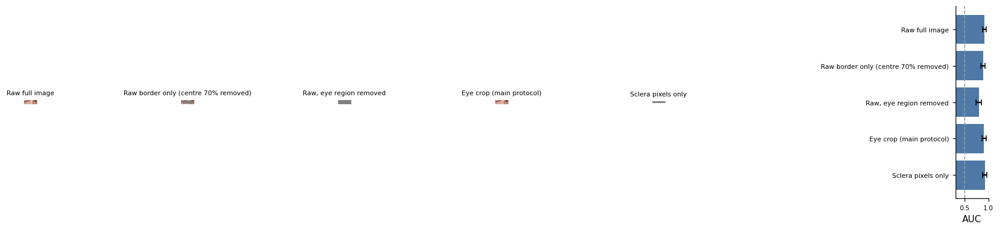

,View,Classifier,AUC,AUC_CI_low,AUC_CI_high
0,Raw full image,frozen dinov2_vits14 + LR,0.919,0.875,0.958
1,Raw border only (centre 70% removed),frozen dinov2_vits14 + LR,0.890,0.840,0.934
2,"Raw, eye region removed",frozen dinov2_vits14 + LR,0.797,0.734,0.857
3,Eye crop (main protocol),frozen dinov2_vits14 + LR,0.907,0.859,0.950
4,Sclera pixels only,frozen dinov2_vits14 + LR,0.924,0.882,0.961
5,Periocular skin colour only,colour features + LR,0.760,0.690,0.825
6,Sclera colour only (same classifier),colour features + LR,0.976,0.959,0.989
7,Raw full image,VGG16 fine-tuned (repeat 1),0.992,0.982,0.999
8,Eye crop (main protocol),VGG16 fine-tuned (repeat 1),0.983,0.957,1.000


In [23]:
def grey_box(im, b, inside=True):
    o = im.copy()
    if inside: o[b[1]:b[3], b[0]:b[2]] = 128
    else: k = np.ones(im.shape[:2], bool); k[b[1]:b[3], b[0]:b[2]] = False; o[k] = 128
    return o
def border_only(im):
    h, w = im.shape[:2]; return grey_box(im, (int(.15 * w), int(.15 * h), int(.85 * w), int(.85 * h)))
VIEWS = {"Raw full image": IMGS, "Raw border only (centre 70% removed)": [border_only(im) for im in IMGS],
         "Raw, eye region removed": [grey_box(im, b) for im, b in zip(IMGS, BOXES)],
         "Eye crop (main protocol)": ECROP, "Sclera pixels only": SMASK}
sc = []
for vname, v in VIEWS.items():
    Ev = E_EYE if vname.startswith("Eye crop") else E_SCL if vname.startswith("Sclera") else embed(v); Pm = np.zeros((R, N))
    for r in range(R):
        for tr, te in splits(CFG["SEED"] + r):
            Pm[r, te] = Pipeline([("sc", StandardScaler()), ("pca", PCA(min(16, len(tr) - 1), random_state=r)),
                                  ("lr", LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))]).fit(Ev[tr], Y[tr]).predict_proba(Ev[te])[:, 1]
    lo, hi = group_bootstrap(Y, Pm.mean(0), GROUPS, roc_auc_score)
    sc.append({"View": vname, "Classifier": f"frozen {BACKBONE_USED} + LR", "AUC": roc_auc_score(Y, Pm.mean(0)), "AUC_CI_low": lo, "AUC_CI_high": hi})
# periocular skin only: colour of the skin around the eye (eye box minus dilated sclera and iris)
skin_feats = []
for im, m, b, ir in zip(IMGS, MASKS, BOXES, [None] * N):
    ring = np.zeros(m.shape, bool); ring[b[1]:b[3], b[0]:b[2]] = True
    ring &= ~cv2.dilate(m.astype(np.uint8), K5, iterations=6).astype(bool)
    L_ = cv2.cvtColor(im, cv2.COLOR_RGB2LAB)[..., 0]; ring &= L_ > np.percentile(L_[ring], 20) if ring.sum() > 50 else ring
    skin_feats.append(colour_features(im, ring))
SKIN = np.stack(skin_feats); Pm = np.zeros((R, N))
for r in range(R):
    for tr, te in splits(CFG["SEED"] + r):
        Pm[r, te] = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))]).fit(SKIN[tr], Y[tr]).predict_proba(SKIN[te])[:, 1]
lo, hi = group_bootstrap(Y, Pm.mean(0), GROUPS, roc_auc_score)
sc.append({"View": "Periocular skin colour only", "Classifier": "colour features + LR", "AUC": roc_auc_score(Y, Pm.mean(0)), "AUC_CI_low": lo, "AUC_CI_high": hi})
Pm = np.zeros((R, N))
for r in range(R):
    for tr, te in splits(CFG["SEED"] + r):
        Pm[r, te] = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))]).fit(HC[tr], Y[tr]).predict_proba(HC[te])[:, 1]
lo, hi = group_bootstrap(Y, Pm.mean(0), GROUPS, roc_auc_score)
sc.append({"View": "Sclera colour only (same classifier)", "Classifier": "colour features + LR", "AUC": roc_auc_score(Y, Pm.mean(0)), "AUC_CI_low": lo, "AUC_CI_high": hi})
if CFG["RAW_CNN_AUDIT"]:
    pr = np.zeros(N); pc = np.zeros(N)
    for tr, te in splits(CFG["SEED"]):
        m_ = train_cnn("vgg16", [IMGS[i] for i in tr], Y[tr], GROUPS[tr], CFG["SEED"]); pr[te] = predict_cnn(m_, [IMGS[i] for i in te]); del m_
    pc = OOF[MODELS[2]][0]
    for vname, p in [("Raw full image", pr), ("Eye crop (main protocol)", pc)]:
        lo, hi = group_bootstrap(Y, p, GROUPS, roc_auc_score)
        sc.append({"View": vname, "Classifier": "VGG16 fine-tuned (repeat 1)", "AUC": roc_auc_score(Y, p), "AUC_CI_low": lo, "AUC_CI_high": hi})
SHORT = pd.DataFrame(sc); SHORT.to_csv(f'{CFG["OUT"]}/table_shortcut_audit.csv', index=False)

k0 = int(np.where(Y == 1)[0][0])
fig = plt.figure(figsize=(15, 3.6)); gsp = fig.add_gridspec(1, 7, width_ratios=[1, 1, 1, 1, 1, .15, 2.6])
for j, (vname, v) in enumerate(VIEWS.items()):
    a = fig.add_subplot(gsp[0, j]); a.imshow(v[k0]); a.set_title(vname, fontsize=7); a.axis("off")
a = fig.add_subplot(gsp[0, 6]); s1 = SHORT[SHORT.Classifier.str.startswith("frozen")]
a.barh(s1.View[::-1], s1.AUC[::-1], xerr=[(s1.AUC - s1.AUC_CI_low)[::-1], (s1.AUC_CI_high - s1.AUC)[::-1]], color="#4e79a7", capsize=3)
a.axvline(0.5, color="#999", ls="--", lw=1); a.set_xlim(0.3, 1); a.set_xlabel("AUC"); a.tick_params(labelsize=7)
savefig("fig08_shortcut_audit")
SHORT.round(3)

## 15. (Optional) External validation
Set `CFG['EXTERNAL_FOLDER']` (sub-folders `jaundice/`, `normal/`). External images go through the same duplicate check against the internal set, OCR filter and CLIPSeg segmentation; models are refitted on all internal data and tested once.

In [ ]:
EXT = None
if CFG["EXTERNAL_FOLDER"] and os.path.isdir(CFG["EXTERNAL_FOLDER"]):
    XI, XY, _ = load_folder(CFG["EXTERNAL_FOLDER"]); n0 = len(XI)
    ok = np.array([min(imagehash.phash(Image.fromarray(im)) - h for h in HASHES) > CFG["PHASH_THR"] for im in XI])
    if CFG["OCR_FILTER"] and "reader" in globals():
        ok &= np.array([not any(c >= CFG["OCR_MIN_CONF"] and len(t.strip()) >= 2 and any(ch.isalpha() for ch in t) for _, t, c in reader.readtext(im)) for im in XI])
    XI = [im for im, k in zip(XI, ok) if k]; XY = XY[ok]
    XM = [auto_sclera(im) for im in XI]; XB = [eye_box(im, m) for im, m in zip(XI, XM)]
    XE = [crop(im, b) for im, b in zip(XI, XB)]; XT = [crop(im, tight_box(im, m)) for im, m in zip(XI, XM)]
    XS = [crop(masked(im, m), tight_box(im, m)) for im, m in zip(XI, XM)]
    XHC = np.stack([colour_features(im, m) for im, m in zip(XI, XM)]); XMHD = np.array([max_hue_degree(im, m) for im, m in zip(XI, XM)]).reshape(-1, 1)
    print(f"external: {n0} loaded, {len(XI)} kept after overlap / text filter")
    s = CFG["SEED"]; pe = {MODELS[0]: fit_b1(HC, Y, XHC, s), MODELS[1]: fit_b2(MHD, Y, XMHD)}
    m3 = train_cnn("vgg16", ECROP, Y, GROUPS, s); pe[MODELS[2]] = predict_cnn(m3, XE); del m3
    m4 = train_cnn("resnet50", STIGHT, Y, GROUPS, s); pe[MODELS[3]] = predict_cnn(m4, XT); del m4
    pe[MODELS[4]] = fit_b5(HC, Y, XHC, s); pe[PROP], _ = fit_sghf(X_SGHF, Y, GROUPS, np.hstack([XHC, embed(XE), embed(XS)]), s)
    EXT = pd.DataFrame([{"Model": m, "n": len(XY), **metrics(XY, p), **dict(zip(["AUC_CI_low", "AUC_CI_high"], group_bootstrap(XY, p, np.arange(len(XY)), roc_auc_score)))} for m, p in pe.items()])
    EXT.to_csv(f'{CFG["OUT"]}/table_external_validation.csv', index=False); display(EXT.round(3))
else: print("No external folder set – skipped (strongly recommended for the journal version).")

## 16. Paper summary, `paper_numbers.json`, download

In [25]:
best = RES.sort_values("AUC", ascending=False).iloc[0]["Model"]
sh = SHORT.set_index(["Classifier", "View"]).AUC
fz = f"frozen {BACKBONE_USED} + LR"
checks = {
  "sclera_source": {"manual": int((SEG_SRC == "manual").sum()), "auto_clipseg": int((SEG_SRC == "auto").sum())},
  "mask_qc_flags_in_final_set": int(QC[QC.id.isin(IDS)].flag.sum()),
  "fallbacks_used": FALLBACKS,
  "best_model_by_AUC": best,
  "proposed_is_best": bool(best == PROP),
  "border_only_AUC": float(sh.get((fz, "Raw border only (centre 70% removed)"), np.nan)),
  "eye_removed_AUC": float(sh.get((fz, "Raw, eye region removed"), np.nan)),
  "sghf_grid_edge_hits": {c: int(BP[c].isin(["96", "16", "3000", "3000.0", "512", "512.0", "0.003", "0.5"]).sum()) for c in BP.columns if c.startswith(("pre__", "clf__C"))},
  "iris_colour_by_class": pd.crosstab(IRIS_COL, Y).to_dict(),
  "periocular_skin_AUC": float(SHORT.set_index("View").AUC.get("Periocular skin colour only", np.nan)),
  "dark_iris_AUC": {m: float(v) for m, v in SUBG[SUBG.Subgroup == "Dark iris only"].set_index("Model").get("AUC", pd.Series(dtype=float)).items() if v == v},
}
out = {"config": CFG, "environment": env, "backbone": BACKBONE_USED, "data_flow": FLOWDF.to_dict("records"),
       "main_results": RES.to_dict("records"), "tests": TESTS.to_dict("records"), "ablation": ABL.to_dict("records"),
       "shortcut_audit": SHORT.to_dict("records"), "subgroups": SUBG.to_dict("records"), "external": None if EXT is None else EXT.to_dict("records"), "checks": checks}
json.dump(out, open(f'{CFG["OUT"]}/paper_numbers.json', "w"), indent=1, default=float)

print("=" * 72); print("DATA FLOW"); print(FLOWDF.to_string(index=False))
print("\nMAIN RESULTS"); print(nice.to_string(index=False))
print("\nTESTS (Holm)"); print(TESTS[["Comparison", "dAUC_DeLong", "p_DeLong_Holm", "p_NB_Holm"]].round(4).to_string(index=False))
print("\nABLATION"); print(ABL[["Variant", "AUC", "AUC_CI_low", "AUC_CI_high"]].round(3).to_string(index=False))
print("\nSHORTCUT AUDIT"); print(SHORT.round(3).to_string(index=False))
print("\nSUBGROUPS (AUC)"); print(SUBG.pivot(index="Model", columns="Subgroup", values="AUC").round(3).to_string() if "AUC" in SUBG else "n/a")
print("\nREADINESS CHECKS"); print(json.dumps(checks, indent=1, default=float))
warn = []
if checks["fallbacks_used"]: warn.append("fallbacks were used – these results are NOT valid for the paper")
if checks["sclera_source"]["manual"] == 0: warn.append("no manual sclera polygons – masks are automatic; annotate for the final paper")
if checks["mask_qc_flags_in_final_set"] > 0: warn.append("some masks are QC-flagged – inspect the QC pages")
if checks["border_only_AUC"] > 0.75: warn.append("border-only AUC is high: the raw images contain shortcuts – report this and keep eye-crop results as the main result")
if checks["periocular_skin_AUC"] > 0.80: warn.append("skin around the eye alone predicts the label well (colour cast / skin tone) – discuss as a limitation")
if checks["dark_iris_AUC"] and min(checks["dark_iris_AUC"].values()) < RES.AUC.min() - 0.1: warn.append("some models drop a lot in the dark-iris subgroup – eye colour was helping them")
if not checks["proposed_is_best"]: warn.append(f"{best} has the highest AUC – do not claim SGHF is best; frame SGHF around calibration / interpretability / statistical equivalence instead")
print("\nWARNINGS:" if warn else "\nNo warnings."); [print(" -", w) for w in warn]

zp = CFG["OUT"].rstrip("/") + ".zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(CFG["OUT"]):
        for f in files: z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), os.path.dirname(CFG["OUT"])))
print("saved:", zp)
try:
    from google.colab import files; files.download(zp)
except Exception: pass

DATA FLOW
                                                       Step  Images  Jaundice  Normal
                                              Images loaded     321       145     176
     After removing near-duplicates with conflicting labels     321       145     176
                   After removing images with overlaid text     289       115     174
        After removing watermark/text images (visual check)     267       100     167
             After removing composite images (visual check)     262        97     165
                 After removing child images (visual check)     256        92     164
After removing failed / excluded masks (final analysis set)     253        90     163

MAIN RESULTS
                Model        AUC (95% CI) Accuracy Sensitivity Specificity    F1   MCC      Brier (95% CI)   ECE
 B1 Mariakakis2017 RF 0.965 (0.943–0.984)    0.897       0.844       0.926 0.854 0.775 0.069 (0.047–0.092) 0.032
    B2 Kihara2023 MHD 0.513 (0.438–0.586)    0.526       0.678

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References
1. Mariakakis A, Banks MA, Phillipi L, Yu L, Taylor J, Patel SN. BiliScreen: smartphone-based scleral jaundice monitoring for liver and pancreatic disorders. *Proc ACM Interact Mob Wearable Ubiquitous Technol.* 2017;1(2):Article 20. doi:10.1145/3090085 *(verify DOI before submission)*
2. Kihara T, Sugihara T, Ikeda S, et al. Identification and quantification of jaundice by trans-conjunctiva optical imaging using a human brain-like algorithm: a cross-sectional study. *Diagnostics.* 2023;13(10):1767. doi:10.3390/diagnostics13101767
3. Althnian A, Almanea N, Aloboud N. Neonatal jaundice diagnosis using a smartphone camera based on eye, skin, and fused features with transfer learning. *Sensors.* 2021;21(21):7038. doi:10.3390/s21217038
4. Park JH, Yang MJ, Kim JS, Park B, Kim JH, Sunwoo MH. Deep-learning-based smartphone application for self-diagnosis of scleral jaundice in patients with hepatobiliary and pancreatic diseases. *J Pers Med.* 2021;11(9):928. doi:10.3390/jpm11090928
5. Seok J, Kim JY, Kim SG, Kim YS, Yoo J-J. Non-invasive jaundice screening using AI: machine learning analysis of sclera and urine images. *J Clin Med.* 2025;14(9):3125. doi:10.3390/jcm14093125
6. Lüddecke T, Ecker A. Image segmentation using text and image prompts (CLIPSeg). *CVPR* 2022.
7. Oquab M, et al. DINOv2: learning robust visual features without supervision. *TMLR* 2024.
8. DeLong ER, DeLong DM, Clarke-Pearson DL. *Biometrics.* 1988;44(3):837–845. · Nadeau C, Bengio Y. *Mach Learn.* 2003;52(3):239–281.
9. Dataset: Ekong D. Diverse Jaundice Eye Dataset, Hugging Face `Bleachcarte/Jaundice_Dataset`, CC BY-NC 4.0.

*Visual exclusion lists:* watermark, composite and child IDs and the finger/glove list were compiled by inspecting every V2 QC page; report them as a supplementary table (`table_manual_exclusions.csv`, `table_image_attributes.csv`).

*Methods notes:* B3 was originally evaluated on neonatal images; B4's CNN architecture is unspecified in the paper (ResNet-50 used); B2 replaces the proprietary ABHB algorithm with an open HSL-hue approximation; B5 re-implements the XGBoost branch of Seok et al.